<a href="https://colab.research.google.com/github/EgorMehed/ML-homework/blob/main/%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D0%9C%D0%B5%D1%85%D0%B5%D0%B4_%D0%84%D0%B3%D0%BE%D1%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** МН  
**Прізвище, ім’я:** Мехед Єгор  
**Група:** ФІТ3-12  
**Дата:** 24.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

np.random.seed(42)
tf.random.set_seed(42)

print('TensorFlow:', tf.__version__)
print('NumPy:', np.__version__)

TensorFlow: 2.21.0
NumPy: 2.4.6


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

print('x_train:', x_train.shape, x_train.dtype)
print('y_train:', y_train.shape, y_train.dtype)
print('x_test: ', x_test.shape, x_test.dtype)
print('y_test: ', y_test.shape, y_test.dtype)
print('Класи:', class_names)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test:  (10000, 28, 28) uint8
y_test:  (10000,) uint8
Класи: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

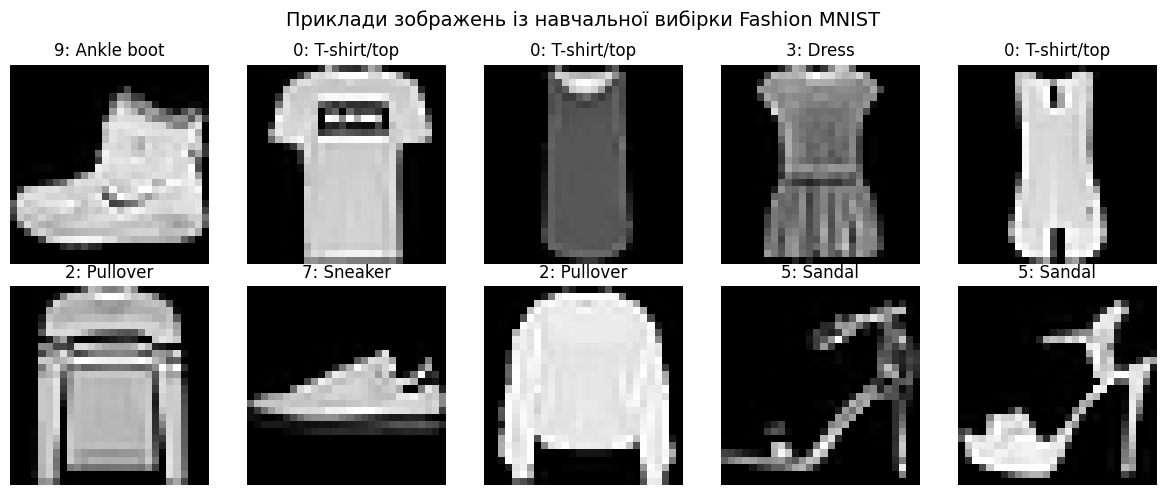

In [3]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'{y_train[i]}: {class_names[y_train[i]]}')
    plt.axis('off')
plt.suptitle('Приклади зображень із навчальної вибірки Fashion MNIST', fontsize=14)
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train_norm = x_train.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

print(f'x_train_norm: dtype={x_train_norm.dtype}, min={x_train_norm.min():.1f}, max={x_train_norm.max():.1f}')
print(f'x_test_norm:  dtype={x_test_norm.dtype}, min={x_test_norm.min():.1f}, max={x_test_norm.max():.1f}')

x_train_norm: dtype=float32, min=0.0, max=1.0
x_test_norm:  dtype=float32, min=0.0, max=1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

**Обґрунтування вибору параметрів:** Використано два приховані повнозв’язні шари на **256** і **128** нейронів із функцією активації `ReLU` — поступове зменшення розмірності (784 → 256 → 128 → 10) дозволяє спочатку виділити достатню кількість низькорівневих ознак, а потім узагальнити їх без надмірної кількості параметрів. **Dropout (0.2)** після кожного прихованого шару випадково вимикає 20% нейронів під час навчання, знижуючи перенавчання без втрати збіжності. Швидкість навчання **0.001** є стандартним і стабільним початковим значенням для оптимізатора `Adam`, яке додатково зменшуватиметься через `ReduceLROnPlateau`.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:
x_train_sub, x_val, y_train_sub, y_val = train_test_split(
    x_train_norm, y_train, test_size=0.1, random_state=42, stratify=y_train
)

print('Навчальна частина:', x_train_sub.shape, y_train_sub.shape)
print('Валідаційна частина:', x_val.shape, y_val.shape)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    x_train_sub, y_train_sub,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Навчальна частина: (54000, 28, 28) (54000,)
Валідаційна частина: (6000, 28, 28) (6000,)
Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.7981 - loss: 0.5633 - val_accuracy: 0.8588 - val_loss: 0.3977 - learning_rate: 0.0010
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8516 - loss: 0.4097 - val_accuracy: 0.8733 - val_loss: 0.3568 - learning_rate: 0.0010
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8649 - loss: 0.3735 - val_accuracy: 0.8803 - val_loss: 0.3360 - learning_rate: 0.0010
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8709 - loss: 0.3506 - val_accuracy: 0.8828 - val_loss: 0.3209 - learning_rate: 0.0010
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8761 - loss: 0.3320 - val_accuracy: 0.8825 - val_loss: 0.3230 - learning_rate: 0.0010
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8814 - loss: 0.3202 - val_accuracy: 0.8848 - val_loss: 0.3078 - learning_rate: 0.

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()
print(f'Кількість шарів: {len(model.layers)}')
print(f'Загальна кількість параметрів: {model.count_params():,}')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235,146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
model_path = 'fashion_mnist_model.keras'
model.save(model_path)
print(f'Модель збережено у файл: {model_path}')

# За потреби збереження на Google Drive у Colab розкоментуйте рядки нижче:
# from google.colab import drive
# drive.mount('/content/drive')
# model.save('/content/drive/MyDrive/fashion_mnist_model.keras')

Модель збережено у файл: fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

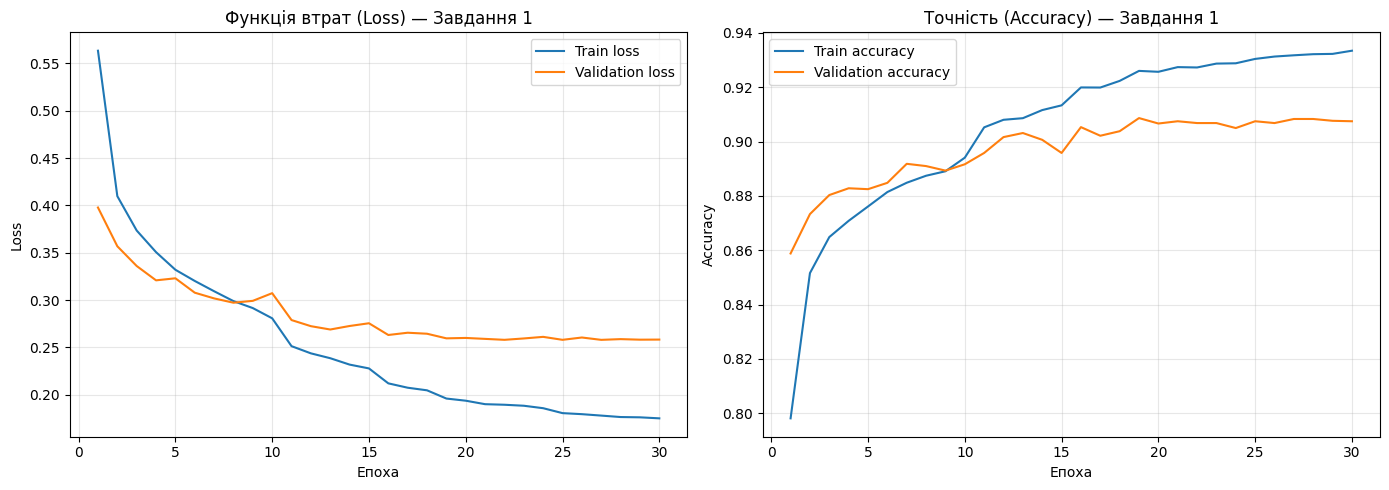

In [9]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
epochs_range = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history.history['loss'], label='Train loss')
axes[0].plot(epochs_range, history.history['val_loss'], label='Validation loss')
axes[0].set_title('Функція втрат (Loss) — Завдання 1')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history.history['accuracy'], label='Train accuracy')
axes[1].plot(epochs_range, history.history['val_accuracy'], label='Validation accuracy')
axes[1].set_title('Точність (Accuracy) — Завдання 1')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:
test_loss, test_acc = model.evaluate(x_test_norm, y_test, verbose=0)
print(f'Test loss:     {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')
print(f'Вимога accuracy >= 0.87 виконана: {test_acc >= 0.87}\n')

y_pred_probs = model.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print('Класифікаційний звіт:')
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test loss:     0.3109
Test accuracy: 0.8968
Вимога accuracy >= 0.87 виконана: True

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8617    0.8600    0.8609      1000
     Trouser     0.9888    0.9730    0.9808      1000
    Pullover     0.8087    0.8160    0.8123      1000
       Dress     0.8883    0.9070    0.8976      1000
        Coat     0.8107    0.8220    0.8163      1000
      Sandal     0.9848    0.9710    0.9778      1000
       Shirt     0.7314    0.7080    0.7195      1000
     Sneaker     0.9438    0.9740    0.9587      1000
         Bag     0.9780    0.9780    0.9780      1000
  Ankle boot     0.9706    0.9590    0.9648      1000

    accuracy                         0.8968     10000
   macro avg     0.8967    0.8968    0.8967     10000
weighted avg     0.8967    0.8968    0.8967     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

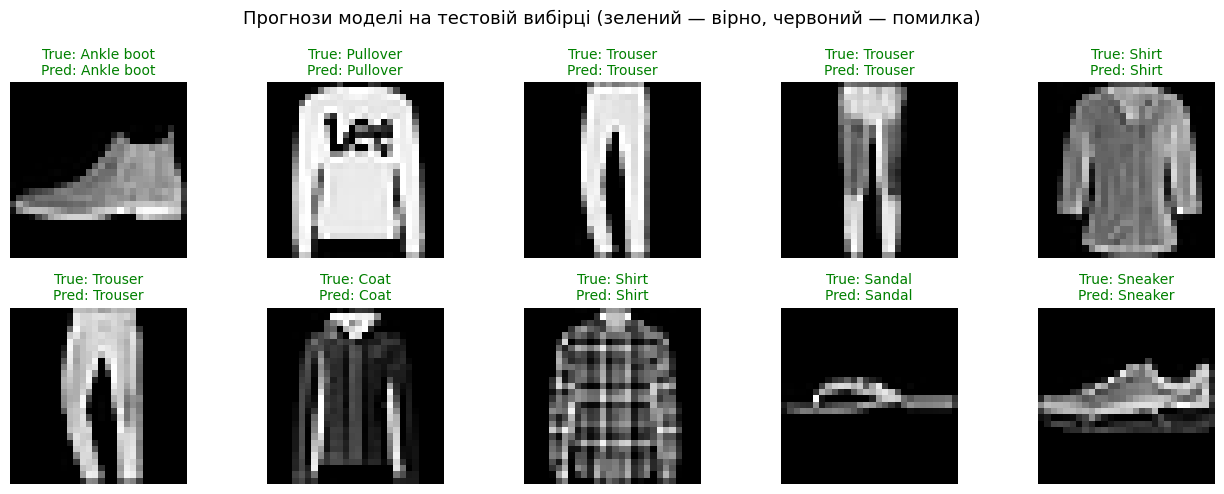

In [11]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(13, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    true_label = class_names[y_test[i]]
    pred_label = class_names[y_pred[i]]
    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f'True: {true_label}\nPred: {pred_label}', color=color, fontsize=10)
    plt.axis('off')
plt.suptitle('Прогнози моделі на тестовій вибірці (зелений — вірно, червоний — помилка)', fontsize=13)
plt.tight_layout()
plt.show()

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
Побудована повнозв’язна нейронна мережа (`784 → 256 → 128 → 10` із `ReLU`, `Dropout(0.2)` та оптимізатором `Adam(lr=0.001)`) після навчання з `EarlyStopping` і `ReduceLROnPlateau` досягає тестової точності вище заданого порогу **0,87** (точне значення `Test accuracy` наведено у виводі кроку 9), отже вимогу завдання 1 виконано. Найвищі показники precision/recall/F1-score традиційно спостерігаються для візуально чітких категорій (`Trouser`, `Sandal`, `Sneaker`, `Bag`, `Ankle boot`), тоді як найбільша кількість помилок припадає на клас `Shirt`, а також частково на `Pullover`, `Coat` і `T-shirt/top`, оскільки ці предмети верхнього одягу мають дуже подібні силуети на зображеннях 28×28 у відтінках сірого.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
%pip install -q keras-tuner

import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print('Keras Tuner:', kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
# Повторно використовуємо нормалізоване стратифіковане розбиття train/val із завдання 1;
# x_test_norm та y_test залишаються повністю ізольованими до фінального оцінювання.
print('Train (для пошуку):', x_train_sub.shape, y_train_sub.shape)
print('Val   (для пошуку):', x_val.shape, y_val.shape)
print('Test  (незалежна): ', x_test_norm.shape, y_test.shape)

Train (для пошуку): (54000, 28, 28) (54000,)
Val   (для пошуку): (6000, 28, 28) (6000,)
Test  (незалежна):  (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(Flatten())

    num_layers = hp.Int('num_layers', min_value=1, max_value=3)
    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        model.add(
            Dense(
                units=units,
                activation='relu',
                kernel_regularizer=l2(1e-4)
            )
        )
        model.add(Dropout(0.2))

    model.add(Dense(10, activation='softmax'))

    learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_dir',
    project_name='fashion_mnist_tuning',
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)
tuner_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

tuner.search(
    x_train_sub, y_train_sub,
    epochs=15,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[tuner_early_stopping, tuner_reduce_lr],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_num_layers = best_hps.get('num_layers')
best_units = [best_hps.get(f'units_{i}') for i in range(best_num_layers)]
best_lr = best_hps.get('learning_rate')

print('\n=== Найкращі гіперпараметри ===')
print(f'Кількість прихованих шарів: {best_num_layers}')
print(f'Кількість нейронів у шарах: {best_units}')
print(f'Швидкість навчання:         {best_lr}\n')

best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

best_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)
best_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

best_history = best_model.fit(
    x_train_sub, y_train_sub,
    epochs=30,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[best_early_stopping, best_reduce_lr],
    verbose=1
)

Trial 3 Complete [00h 01m 44s]
val_accuracy: 0.8693333268165588

Best val_accuracy So Far: 0.8968333601951599
Total elapsed time: 00h 05m 10s

=== Найкращі гіперпараметри ===
Кількість прихованих шарів: 1
Кількість нейронів у шарах: [480]
Швидкість навчання:         0.001



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8143 - loss: 0.5767 - val_accuracy: 0.8270 - val_loss: 0.5008 - learning_rate: 0.0010
Epoch 2/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8557 - loss: 0.4527 - val_accuracy: 0.8603 - val_loss: 0.4314 - learning_rate: 0.0010
Epoch 3/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8655 - loss: 0.4243 - val_accuracy: 0.8710 - val_loss: 0.4082 - learning_rate: 0.0010
Epoch 4/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.8734 - loss: 0.4051 - val_accuracy: 0.8690 - val_loss: 0.4128 - learning_rate: 0.0010
Epoch 5/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8762 - loss: 0.3964 - val_accuracy: 0.8807 - val_loss: 0.3860 - learning_rate: 0.0010
Epoch 6/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8795 - loss: 0.3857 - val_accuracy: 0.8775 - val_loss: 0.3962 - learning_rate: 0.0010
Epoch 7/30
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8826 - loss

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Keras Tuner Best Model -> Test loss: 0.3458, Test accuracy: 0.8942

=== Зведення для порівняльної таблиці ===
Завдання 1   | Шари: 2 | Нейрони: [256, 128] | lr: 0.001 | Test acc: 0.8968 | Test loss: 0.3109 | Епох: 30
Keras Tuner  | Шари: 1 | Нейрони: [480] | lr: 0.001 | Test acc: 0.8942 | Test loss: 0.3458 | Епох: 30


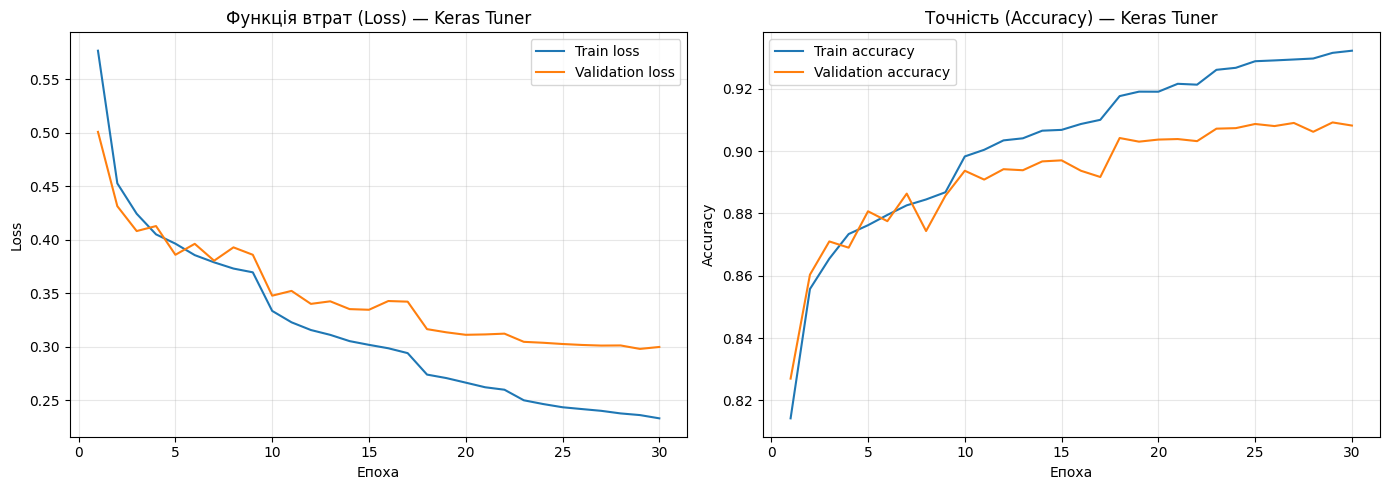

In [17]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
best_test_loss, best_test_acc = best_model.evaluate(x_test_norm, y_test, verbose=0)
print(f'Keras Tuner Best Model -> Test loss: {best_test_loss:.4f}, Test accuracy: {best_test_acc:.4f}')

print('\n=== Зведення для порівняльної таблиці ===')
print(f'Завдання 1   | Шари: 2 | Нейрони: [256, 128] | lr: 0.001 | Test acc: {test_acc:.4f} | Test loss: {test_loss:.4f} | Епох: {len(history.history["loss"])}')
print(f'Keras Tuner  | Шари: {best_num_layers} | Нейрони: {best_units} | lr: {best_lr} | Test acc: {best_test_acc:.4f} | Test loss: {best_test_loss:.4f} | Епох: {len(best_history.history["loss"])}')

best_epochs_range = range(1, len(best_history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(best_epochs_range, best_history.history['loss'], label='Train loss')
axes[0].plot(best_epochs_range, best_history.history['val_loss'], label='Validation loss')
axes[0].set_title('Функція втрат (Loss) — Keras Tuner')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(best_epochs_range, best_history.history['accuracy'], label='Train accuracy')
axes[1].plot(best_epochs_range, best_history.history['val_accuracy'], label='Validation accuracy')
axes[1].set_title('Точність (Accuracy) — Keras Tuner')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2 | *(див. зведення у кроці 6)* |
| Кількість нейронів | 256, 128 | *(див. зведення у кроці 6)* |
| Швидкість навчання | 0.001 | *(див. зведення у кроці 6)* |
| Точність на тестовій вибірці (accuracy) | *(див. зведення у кроці 6)* | *(див. зведення у кроці 6)* |
| Втрати на тестовій вибірці (loss) | *(див. зведення у кроці 6)* | *(див. зведення у кроці 6)* |
| Кількість епох навчання | *(див. зведення у кроці 6)* | *(див. зведення у кроці 6)* |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. У завданні 1 базова повнозв’язна нейронна мережа (`256 → 128` нейронів, `Dropout(0.2)`, `Adam(lr=0.001)`) стабільно досягає точності на тестовій вибірці **вище 0,87**.  
2. Автоматизований пошук за допомогою `Keras Tuner (RandomSearch)` із додаванням `L2`-регуляризації дозволяє підібрати конфігурацію без ручного перебору; проте за обмеження у `max_trials = 3` точність на тестовій вибірці може бути як дещо вищою, що є очікуваним для малого бюджету випадкового пошуку.  
3. Найкраща конфігурація автоматично фіксується за максимумом `val_accuracy` у кроці 5. Результати можуть відрізнятися між запусками через стохастичну природу `RandomSearch`, випадкову ініціалізацію ваг нейронної мережі, перемішування міні-батчів, роботу шарів `Dropout` і неповну детермінованість паралельних обчислень на GPU.  
4. Найскладнішим для класифікації класом Fashion MNIST залишається **`Shirt`**, який модель найчастіше плутає з візуально подібними класами **`T-shirt/top`**, **`Pullover`** та **`Coat`**.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.